# Step 1:Importing liabraries
Importing liabraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


# Step 2: Load the IoT dataset
Read the combined IoT network traffic CSV and inspect the first rows.

In [2]:
df = pd.read_csv('iot23_combined_new.csv')
df.head()



C:\Users\gariy\AppData\Local\Temp\ipykernel_18128\3456653864.py:1: DtypeWarning: Columns (0: duration, 1: orig_bytes, 2: resp_bytes) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv('iot23_combined_new.csv')


,Unnamed: 0,ts,uid,id.orig_h,id.orig_p,id.resp_h,id.resp_p,proto,service,duration,...,conn_state,local_orig,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label
0,0,1.536227e+09,CeqqKl3hyLQmO8LK98,192.168.100.111,17576.0,78.1.220.212,8081.0,tcp,-,0.000003,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
1,1,1.536227e+09,C2oHQWo1EFGH8D9x7,192.168.100.111,17576.0,152.84.7.111,8081.0,tcp,-,0.000002,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
2,2,1.536227e+09,CJLVjs4BByG04mczXc,192.168.100.111,17576.0,173.36.41.67,8081.0,tcp,-,0.000002,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
3,3,1.536227e+09,C0z4uS9AWHDH2s4S7,192.168.100.111,17576.0,87.13.21.104,8081.0,tcp,-,0.000002,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
4,4,1.536227e+09,CxbNVk3liFNUIlqSPi,192.168.100.111,17576.0,99.110.163.140,8081.0,tcp,-,0.000002,...,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan


In [3]:
df.isnull().sum()


Unnamed: 0       0
ts               0
uid              0
id.orig_h        0
id.orig_p        0
id.resp_h        0
id.resp_p        0
proto            0
service          0
duration         0
orig_bytes       0
resp_bytes       0
conn_state       0
local_orig       0
local_resp       0
missed_bytes     0
history          0
orig_pkts        0
orig_ip_bytes    0
resp_pkts        0
resp_ip_bytes    0
label            0
dtype: int64

# Step 3: Inspect data quality
Check for missing values, dataset size, data types, and label distribution.

In [4]:
df.shape

(6046623, 22)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6046623 entries, 0 to 6046622
Data columns (total 22 columns):
 #   Column         Dtype  
---  ------         -----  
 0   Unnamed: 0     int64  
 1   ts             float64
 2   uid            str    
 3   id.orig_h      str    
 4   id.orig_p      float64
 5   id.resp_h      str    
 6   id.resp_p      float64
 7   proto          str    
 8   service        str    
 9   duration       object 
 10  orig_bytes     object 
 11  resp_bytes     object 
 12  conn_state     str    
 13  local_orig     str    
 14  local_resp     str    
 15  missed_bytes   float64
 16  history        str    
 17  orig_pkts      float64
 18  orig_ip_bytes  float64
 19  resp_pkts      float64
 20  resp_ip_bytes  float64
 21  label          str    
dtypes: float64(8), int64(1), object(3), str(10)
memory usage: 1014.9+ MB


In [6]:
df['label'].value_counts()

label
PartOfAHorizontalPortScan     3389036
Okiru                         1313012
Benign                         688812
DDoS                           638506
C&C                             15286
C&C-HeartBeat                    1332
Attack                            538
C&C-FileDownload                   46
C&C-Torii                          30
FileDownload                       13
C&C-HeartBeat-FileDownload          8
Okiru-Attack                        3
C&C-Mirai                           1
Name: count, dtype: int64

In [7]:
drop_cols = [
    
    'uid',
    'id.orig_h',
    'id.resp_h',
    'ts'
]

# Step 4: Remove irrelevant metadata
Drop identifiers and timestamp columns that are not useful for model training.

In [8]:
df1=df.drop(['Unnamed: 0', 'uid', 'id.orig_h', 'id.resp_h', 'ts'],  axis=1 )

In [9]:
df1.head()

,id.orig_p,id.resp_p,proto,service,duration,orig_bytes,resp_bytes,conn_state,local_orig,local_resp,missed_bytes,history,orig_pkts,orig_ip_bytes,resp_pkts,resp_ip_bytes,label
0,17576.0,8081.0,tcp,-,0.000003,0,0,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
1,17576.0,8081.0,tcp,-,0.000002,0,0,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
2,17576.0,8081.0,tcp,-,0.000002,0,0,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
3,17576.0,8081.0,tcp,-,0.000002,0,0,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan
4,17576.0,8081.0,tcp,-,0.000002,0,0,S0,-,-,0.0,S,2.0,80.0,0.0,0.0,PartOfAHorizontalPortScan


# Step 5: Clean numeric fields
Replace placeholder values, then convert duration and byte counts to numeric form.

In [10]:
df1.shape

(6046623, 17)

In [11]:
df1['label'].value_counts()

label
PartOfAHorizontalPortScan     3389036
Okiru                         1313012
Benign                         688812
DDoS                           638506
C&C                             15286
C&C-HeartBeat                    1332
Attack                            538
C&C-FileDownload                   46
C&C-Torii                          30
FileDownload                       13
C&C-HeartBeat-FileDownload          8
Okiru-Attack                        3
C&C-Mirai                           1
Name: count, dtype: int64

In [12]:
df1.info()

<class 'pandas.DataFrame'>
RangeIndex: 6046623 entries, 0 to 6046622
Data columns (total 17 columns):
 #   Column         Dtype  
---  ------         -----  
 0   id.orig_p      float64
 1   id.resp_p      float64
 2   proto          str    
 3   service        str    
 4   duration       object 
 5   orig_bytes     object 
 6   resp_bytes     object 
 7   conn_state     str    
 8   local_orig     str    
 9   local_resp     str    
 10  missed_bytes   float64
 11  history        str    
 12  orig_pkts      float64
 13  orig_ip_bytes  float64
 14  resp_pkts      float64
 15  resp_ip_bytes  float64
 16  label          str    
dtypes: float64(7), object(3), str(7)
memory usage: 784.2+ MB


In [13]:
df1['duration'].unique()[:20]
df1['orig_bytes'].unique()[:20]

array([0, 96, 80, 56, 88, 136, 1008, 168, 84, '0', '96', '56', '80', '78',
       '90', '39', '-', '45', '76', '38'], dtype=object)

In [14]:
df2=df1.replace('-', np.nan, inplace=True)

# Step 6: Inspect cleaned data
Check the dataset after placeholder replacement and type conversion before dropping extra columns.

In [15]:
df2.isnull().sum()

id.orig_p              0
id.resp_p              0
proto                  0
service          6038628
duration         3773928
orig_bytes       3773928
resp_bytes       3773928
conn_state             0
local_orig       6046623
local_resp       6046623
missed_bytes           0
history             1610
orig_pkts              0
orig_ip_bytes          0
resp_pkts              0
resp_ip_bytes          0
label                  0
dtype: int64

In [16]:
for col in ['duration', 'orig_bytes', 'resp_bytes']:
    df2[col] = pd.to_numeric(df2[col], errors='coerce')

In [17]:
df2[['duration','orig_bytes','resp_bytes']].dtypes

duration      float64
orig_bytes    float64
resp_bytes    float64
dtype: object

In [18]:
df2.isnull().sum()

id.orig_p              0
id.resp_p              0
proto                  0
service          6038628
duration         3773928
orig_bytes       3773928
resp_bytes       3773928
conn_state             0
local_orig       6046623
local_resp       6046623
missed_bytes           0
history             1610
orig_pkts              0
orig_ip_bytes          0
resp_pkts              0
resp_ip_bytes          0
label                  0
dtype: int64

# Step 7: Drop unnecessary features
Remove columns such as local network flags and service fields that are not used by the model.

In [19]:
df2.drop(
    ['local_orig', 'local_resp'],
    axis=1,
    inplace=True
)

In [20]:
df2.drop('service', axis=1, inplace=True)

In [21]:


df2['history'].fillna(df2['history'].mode()[0], inplace=True)

C:\Users\gariy\AppData\Local\Temp\ipykernel_18128\1494605272.py:1: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df2['history'].fillna(df2['history'].mode()[0], inplace=True)


0          S
1          S
2          S
3          S
4          S
          ..
6046618    D
6046619    S
6046620    S
6046621    S
6046622    S
Name: history, Length: 6046623, dtype: str

In [22]:
# Create missing indicators first
df2['duration_missing'] = df2['duration'].isna().astype(int)
df2['orig_bytes_missing'] = df2['orig_bytes'].isna().astype(int)
df2['resp_bytes_missing'] = df2['resp_bytes'].isna().astype(int)

# Fill numeric missing values
df2['duration'] = df2['duration'].fillna(0)
df2['orig_bytes'] = df2['orig_bytes'].fillna(0)
df2['resp_bytes'] = df2['resp_bytes'].fillna(0)

# Fill history
df2['history'] = df2['history'].fillna(df2['history'].mode()[0])

In [23]:
df2.shape

(6046623, 17)

# Step 10: Map and group attack labels
Group related attack types into broader categories for final classification.

In [24]:
print(df2.shape)

print(df2[['proto','conn_state','history']].nunique())

print(df2[['proto','conn_state','history']].head())

(6046623, 17)
proto           3
conn_state     13
history       139
dtype: int64
  proto conn_state history
0   tcp         S0       S
1   tcp         S0       S
2   tcp         S0       S
3   tcp         S0       S
4   tcp         S0       S


# Step 9: Encode categorical variables
Convert protocol, connection state, history, and labels into numeric format.

In [25]:
from sklearn.preprocessing import LabelEncoder

le_proto = LabelEncoder()
le_conn = LabelEncoder()
le_hist = LabelEncoder()
le_label = LabelEncoder()

df2['proto'] = le_proto.fit_transform(df2['proto'])
df2['conn_state'] = le_conn.fit_transform(df2['conn_state'])
df2['history'] = le_hist.fit_transform(df2['history'])
df2['label'] = le_label.fit_transform(df2['label'])

In [26]:
df2['label'].value_counts()

label
12    3389036
10    1313012
1      688812
8      638506
2       15286
4        1332
0         538
3          46
7          30
9          13
5           8
11          3
6           1
Name: count, dtype: int64

In [27]:
for i, c in enumerate(le_label.classes_):
    print(i, c)

0 Attack
1 Benign
2 C&C
3 C&C-FileDownload
4 C&C-HeartBeat
5 C&C-HeartBeat-FileDownload
6 C&C-Mirai
7 C&C-Torii
8 DDoS
9 FileDownload
10 Okiru
11 Okiru-Attack
12 PartOfAHorizontalPortScan


# Step 10: Map and group attack labels
Group related attack types into broader categories for final classification.

In [28]:
mapping = {
    'Attack':'Attack',
    'FileDownload':'Attack',
    'Okiru-Attack':'Attack',

    'C&C':'C&C',
    'C&C-HeartBeat':'C&C',
    'C&C-FileDownload':'C&C',
    'C&C-HeartBeat-FileDownload':'C&C',
    'C&C-Torii':'C&C',
    'C&C-Mirai':'C&C',

    'Benign':'Benign',
    'DDoS':'DDoS',
    'Okiru':'Okiru',
    'PartOfAHorizontalPortScan':'PortScan'
}

# Step 10: Map and group attack labels
Group related attack types into broader categories for final classification.

In [29]:
print(le_label.classes_)

['Attack' 'Benign' 'C&C' 'C&C-FileDownload' 'C&C-HeartBeat'
 'C&C-HeartBeat-FileDownload' 'C&C-Mirai' 'C&C-Torii' 'DDoS'
 'FileDownload' 'Okiru' 'Okiru-Attack' 'PartOfAHorizontalPortScan']


In [30]:
mapping = {
    1: 'Benign',      # Benign
    8: 'DDoS',        # DDoS
    12: 'PortScan',   # PartOfAHorizontalPortScan
    10: 'Okiru',      # Okiru

    0: 'Malware',     # Attack
    2: 'Malware',     # C&C
    3: 'Malware',     # C&C-FileDownload
    4: 'Malware',     # C&C-HeartBeat
    5: 'Malware',     # C&C-HeartBeat-FileDownload
    6: 'Malware',     # C&C-Mirai
    7: 'Malware',     # C&C-Torii
    9: 'Malware',     # FileDownload
    11: 'Malware'     # Okiru-Attack
}

df2['new_label'] = df2['label'].map(mapping)

In [31]:
df2['new_label'].value_counts()

new_label
PortScan    3389036
Okiru       1313012
Benign       688812
DDoS         638506
Malware       17257
Name: count, dtype: int64

In [32]:
print(df2.columns)

Index(['id.orig_p', 'id.resp_p', 'proto', 'duration', 'orig_bytes',
       'resp_bytes', 'conn_state', 'missed_bytes', 'history', 'orig_pkts',
       'orig_ip_bytes', 'resp_pkts', 'resp_ip_bytes', 'label',
       'duration_missing', 'orig_bytes_missing', 'resp_bytes_missing',
       'new_label'],
      dtype='str')


# Step 11: Balance class distribution
Sample each class equally so the model trains fairly on all traffic types.

In [33]:
min_class_size = df2['new_label'].value_counts().min()

balanced_df = df2.groupby(
    'new_label',
    group_keys=False
).sample(
    n=min_class_size,
    random_state=42
)

balanced_df = balanced_df.reset_index(drop=True)

print(balanced_df['new_label'].value_counts())
print(balanced_df.shape)

new_label
Benign      17257
DDoS        17257
Malware     17257
Okiru       17257
PortScan    17257
Name: count, dtype: int64
(86285, 18)


In [34]:
print("Before:", balanced_df.shape)

balanced_df = balanced_df.drop_duplicates()

print("After:", balanced_df.shape)

Before: (86285, 18)
After: (44558, 18)


In [35]:
balanced_df['new_label'].value_counts()

new_label
Malware     13057
DDoS        12031
Benign      11712
PortScan     7727
Okiru          31
Name: count, dtype: int64

In [36]:
balanced_df['new_label'] = balanced_df['new_label'].replace(
    'Okiru',
    'Malware'
)

balanced_df['new_label'].value_counts()

new_label
Malware     13088
DDoS        12031
Benign      11712
PortScan     7727
Name: count, dtype: int64

In [37]:
min_class_size = balanced_df['new_label'].value_counts().min()

final_df = balanced_df.groupby(
    'new_label',
    group_keys=False
).sample(
    n=min_class_size,
    random_state=42
).reset_index(drop=True)

print(final_df['new_label'].value_counts())

new_label
Benign      7727
DDoS        7727
Malware     7727
PortScan    7727
Name: count, dtype: int64


# Step 12: Prepare training data
Encode the final labels and build the feature matrix and target vector.

In [38]:
from sklearn.preprocessing import LabelEncoder

target_encoder = LabelEncoder()

final_df['target'] = target_encoder.fit_transform(
    final_df['new_label']
)

In [39]:
X = final_df.drop(
    columns=['label', 'new_label', 'target']
)

y = final_df['target']

# Step 13: Train-Test Split

In [40]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)

(24726, 16)
(6182, 16)


# Step 14: Train the model
Fit the RandomForest classifier on the training dataset.

In [41]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train, y_train)

,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total

# Step 15: Predict and evaluate
Generate test predictions and calculate accuracy and related metrics.

In [42]:
y_pred = rf.predict(X_test)

In [43]:
from sklearn.metrics import accuracy_score

acc = accuracy_score(y_test, y_pred)

print("Accuracy:", acc)

Accuracy: 0.998220640569395


# Step 16: Evaluate model outputs
Visualize the confusion matrix and print the classification report.

Text(0.5, 1.0, 'Confusion Matrix')

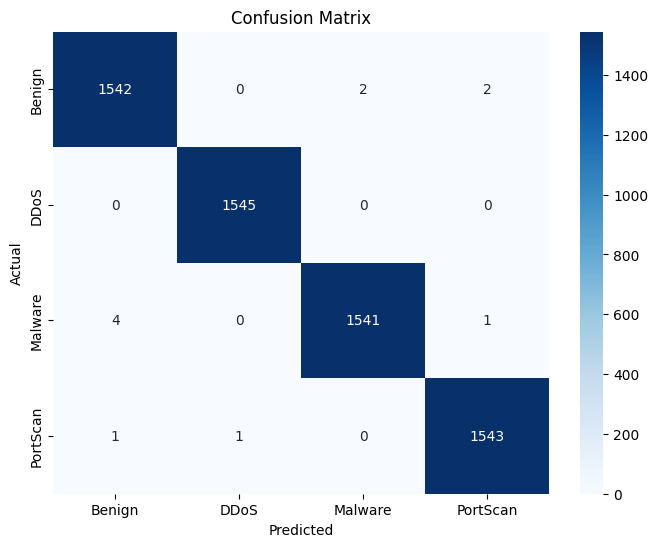

In [55]:
import seaborn as sns
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=target_encoder.classes_,
    yticklabels=target_encoder.classes_
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

# plt.show()

In [56]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_test,
        y_pred,
        target_names=target_encoder.classes_,
        digits=6
    )
)

              precision    recall  f1-score   support

      Benign   0.996768  0.997413  0.997090      1546
        DDoS   0.999353  1.000000  0.999676      1545
     Malware   0.998704  0.996766  0.997734      1546
    PortScan   0.998060  0.998706  0.998382      1545

    accuracy                       0.998221      6182
   macro avg   0.998221  0.998221  0.998221      6182
weighted avg   0.998221  0.998221  0.998220      6182



# Step 17: Save model artifacts
Export the trained model and label encoder so they can be reused later.

In [47]:
import joblib

joblib.dump(rf, 'iot23_ids_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [48]:
joblib.dump(target_encoder, 'target_encoder.pkl')

print("Target encoder saved!")

Target encoder saved!


# Step 18: Test sample prediction
Load saved artifacts and run a sample network record through the model.

In [49]:

# Load model
model = joblib.load("iot23_ids_model.pkl")


# Step 19: Test sample prediction
Load saved artifacts and run a sample network record through the model.

In [50]:
# Load target encoder
target_encoder = joblib.load("target_encoder.pkl")

In [57]:
scan_record = pd.DataFrame([{
'id.orig_p': 17576,
'id.resp_p': 8081,
'proto': 1,
'duration': 0.000002,
'orig_bytes': 80,
'resp_bytes': 0,
'conn_state': 11,
'missed_bytes': 0,
'history': 80,
'orig_pkts': 2,
'orig_ip_bytes': 80,
'resp_pkts': 0,
'resp_ip_bytes': 0,
'duration_missing': 0,
'orig_bytes_missing': 0,
'resp_bytes_missing': 0
}])

pred = model.predict(scan_record)

print(
    "Predicted Traffic Type:",
    target_encoder.inverse_transform(pred)[0]
)

Predicted Traffic Type: Benign


In [ ]:
scan_record = pd.DataFrame([{
'id.orig_p': 17576,
'id.resp_p': 8081,
'proto': 1,
'duration': 0.000002,
'orig_bytes': 81550,
'resp_bytes': 0,
'conn_state': 15551,
'missed_bytes': 0,
'history': 80,
'orig_pkts': 2,
'orig_ip_bytes': 80,
'resp_pkts': 0,
'resp_ip_bytes': 0,
'duration_missing': 0,
'orig_bytes_missing': 0,
'resp_bytes_missing': 0
}])

pred = model.predict(scan_record)

print(
    "Predicted Traffic Type:",
    target_encoder.inverse_transform(pred)[0]
)

Predicted Traffic Type: Benign
